# Asset-Based Orchestration with Dagster

Task-based orchestrators (Airflow, Lessons 05–07) describe **what to run**. **Dagster** describes **what should exist**: data **assets** (tables, files, models) and how each one is computed from others. The orchestrator derives the run order, tracks when each asset was last materialised, and attaches checks and metadata to the asset itself.

**After this lesson you can:**

1. Define software-defined assets and their dependencies in Python.
2. Materialise assets, read their metadata, and add asset checks.
3. Partition an asset by day and materialise individual partitions (backfills).
4. Compare asset-based and task-based orchestration.

**Data:** NYC taxi trips, January–February 2024, and the zone lookup. Dagster runs **in-process** here (no server needed); `dagster dev` would add the web UI.

In [1]:
import contextlib
import io
import sys
import tempfile
import time
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
WORK = Path(tempfile.mkdtemp())

@contextlib.contextmanager
def quiet():
    """Collect the verbose log output of a tool (stderr) instead of printing it in the notebook."""
    buf = io.StringIO()
    with contextlib.redirect_stderr(buf):
        yield buf

import dagster as dg

print("Dagster", dg.__version__)
DB = str(WORK / "dagster_warehouse.duckdb")

Dagster 1.13.30


## 1. Assets and Dependencies

An asset is a decorated function. Its parameters name the upstream assets it needs, so Dagster builds the graph from the function signatures.

In [2]:
@dg.asset(description="Raw zone lookup loaded from the TLC CSV.", group_name="raw")
def raw_zones() -> pd.DataFrame:
    return pd.read_csv(datasets.fetch("taxi_zone_lookup.csv"))

@dg.asset(description="Cleaned trips of January 2024.", group_name="staging")
def stg_trips() -> pd.DataFrame:
    df = pd.read_parquet(datasets.taxi("2024-01"), columns=["tpep_pickup_datetime", "PULocationID", "fare_amount", "total_amount"])
    keep = df["tpep_pickup_datetime"].between("2024-01-01", "2024-02-01", inclusive="left") & df["fare_amount"].between(3, 500)
    return df[keep].rename(columns={"tpep_pickup_datetime": "pickup_at", "PULocationID": "zone_id"})

@dg.asset(description="Revenue per borough and day.", group_name="marts")
def borough_daily_revenue(context: dg.AssetExecutionContext, stg_trips: pd.DataFrame, raw_zones: pd.DataFrame) -> pd.DataFrame:
    out = (stg_trips.merge(raw_zones[["LocationID", "Borough"]], left_on="zone_id", right_on="LocationID")
                    .assign(day=lambda d: d["pickup_at"].dt.date)
                    .groupby(["Borough", "day"], as_index=False)["total_amount"].sum())
    context.add_output_metadata({"rows": len(out), "boroughs": out["Borough"].nunique(),
                                 "total_revenue_musd": round(float(out["total_amount"].sum()) / 1e6, 2)})
    return out

@dg.asset_check(asset=borough_daily_revenue, description="Every day of January must have Manhattan revenue.")
def manhattan_every_day(borough_daily_revenue: pd.DataFrame) -> dg.AssetCheckResult:
    days = borough_daily_revenue.loc[borough_daily_revenue["Borough"] == "Manhattan", "day"].nunique()
    return dg.AssetCheckResult(passed=days == 31, metadata={"days_with_revenue": days})

defs = dg.Definitions(assets=[raw_zones, stg_trips, borough_daily_revenue], asset_checks=[manhattan_every_day])
graph = {k.to_user_string(): [d.to_user_string() for d in v] for k, v in
         defs.resolve_asset_graph().asset_dep_graph["upstream"].items()}
print(graph)

{'borough_daily_revenue': ['stg_trips', 'raw_zones'], 'raw_zones': [], 'stg_trips': []}


## 2. Materialise and Inspect

`dg.materialize()` runs the assets in dependency order and returns events: materialisations with metadata, check results, timings.

In [3]:
with quiet():
    t = time.perf_counter()
    result = dg.materialize([raw_zones, stg_trips, borough_daily_revenue, manhattan_every_day])
    run_s = time.perf_counter() - t
print("success:", result.success, f"({run_s:.1f} s)")
for ev in result.get_asset_materialization_events():
    mat = ev.event_specific_data.materialization
    meta = {k: v.value for k, v in mat.metadata.items()}
    print(f"  materialised {mat.asset_key.to_user_string():<22} {meta if meta else ''}")
for chk in result.get_asset_check_evaluations():
    print(f"  check {chk.check_name}: {'passed' if chk.passed else 'FAILED'} {({k: v.value for k, v in chk.metadata.items()})}")

success: True (25.1 s)
  materialised raw_zones              {'path': '/tmp/tmp5mb7rdaa/storage/raw_zones'}
  materialised stg_trips              {'path': '/tmp/tmp5mb7rdaa/storage/stg_trips'}
  materialised borough_daily_revenue  {'rows': 214, 'boroughs': 7, 'total_revenue_musd': 80.13, 'path': '/tmp/tmp5mb7rdaa/storage/borough_daily_revenue'}
  check manhattan_every_day: passed {'days_with_revenue': 31}


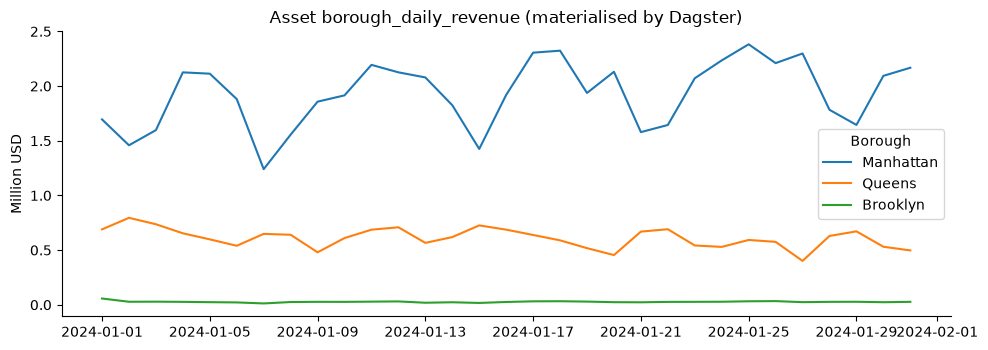

In [4]:
rev = result.output_for_node("borough_daily_revenue")
p = rev.pivot(index="day", columns="Borough", values="total_amount")[["Manhattan", "Queens", "Brooklyn"]] / 1e6
p.plot(figsize=(10, 3.6), title="Asset borough_daily_revenue (materialised by Dagster)", ylabel="Million USD", xlabel="")
plt.tight_layout()
plt.show()

## 3. Partitions and Backfills

Large assets are split into **partitions**, usually by time. Each partition is materialised (and re-materialised) on its own: a daily schedule computes today's partition; a **backfill** computes a range of past partitions; a bug fix re-runs only the affected days.

In [5]:
daily = dg.DailyPartitionsDefinition(start_date="2024-02-01", end_date="2024-03-01")

@dg.asset(partitions_def=daily, description="Trips and revenue for one day, stored in DuckDB.")
def daily_trip_stats(context: dg.AssetExecutionContext) -> dg.MaterializeResult:
    day = context.partition_key
    con = duckdb.connect(DB)
    con.execute("CREATE TABLE IF NOT EXISTS daily_trip_stats (day DATE PRIMARY KEY, trips BIGINT, revenue DOUBLE)")
    row = con.execute(f"""SELECT count(*), sum(total_amount) FROM read_parquet('{datasets.taxi('2024-02')}')
                          WHERE CAST(tpep_pickup_datetime AS DATE) = DATE '{day}' AND fare_amount BETWEEN 3 AND 500""").fetchone()
    con.execute("INSERT OR REPLACE INTO daily_trip_stats VALUES (?, ?, ?)", [day, row[0], row[1]])   # idempotent per partition
    con.close()
    return dg.MaterializeResult(metadata={"trips": int(row[0])})

print("partitions:", len(daily.get_partition_keys()), "| first:", daily.get_partition_keys()[0], "| last:", daily.get_partition_keys()[-1])
with quiet():
    t = time.perf_counter()
    for key in daily.get_partition_keys()[:14]:                 # backfill the first two weeks
        dg.materialize([daily_trip_stats], partition_key=key)
    dg.materialize([daily_trip_stats], partition_key="2024-02-03")   # re-run one day: no duplicates
print(f"backfilled 14 partitions + 1 re-run in {time.perf_counter() - t:.1f} s")
con = duckdb.connect(DB, read_only=True)
print(con.sql("SELECT count(*) AS days, count(DISTINCT day) AS distinct_days, sum(trips) AS trips FROM daily_trip_stats").df())
con.close()

partitions: 29 | first: 2024-02-01 | last: 2024-02-29


backfilled 14 partitions + 1 re-run in 78.3 s
   days  distinct_days      trips
0    14             14  1403835.0


## 4. Assets vs Tasks

| | Task-based (Airflow) | Asset-based (Dagster; also Airflow 3 assets) |
| :--- | :--- | :--- |
| unit | a task that runs code | a data asset that should exist |
| dependencies | declared between tasks | derived from asset inputs |
| freshness | "did the task succeed?" | "when was this table last updated, from which inputs?" |
| quality | separate tasks | checks attached to the asset |
| backfills | re-run DAG runs for dates | materialise partitions of an asset |
| local testing | DAG runs in a scheduler | `materialize()` in a test or notebook |

*Insight: Think of a pipeline as a set of data assets with definitions, not as a list of jobs. Asset-based orchestration makes lineage, freshness, partition backfills and quality checks first-class, and lets you test pipelines like normal Python functions.*

## Real-World Use Case or Analogy

Task-based orchestration is like a **to-do list** ("cook rice, then fry vegetables"); asset-based orchestration is like a **menu with recipes** ("fried rice needs rice and vegetables"). The kitchen works out the order, knows when each dish was last made, and can remake one portion without cooking the whole menu again.

Data platforms with many interdependent tables, ML features and models adopt Dagster for this model; Airflow 3 added assets for the same reason (Lesson 07).